In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

nist_spectra_df = pd.read_pickle('../../data/proc/nist20/spec_df.pkl')
nist_spectra_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,NaN,1467.0061,"[(45.96, 46.35), (597.48, 51.85), (598.5, 41.3...",NaN,0,NaN,NaN,NaN,NaN,single
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,NaN,1467.0061,"[(597.5, 50.95), (599.5, 683.32), (1449.98, 99...",NaN,0,NaN,NaN,NaN,NaN,single
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,NaN,1467.0061,"[(537.39, 55.94), (599.5, 999.0), (600.51, 42....",NaN,0,NaN,NaN,NaN,NaN,single
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,NaN,1467.0061,"[(597.46, 41.86), (598.5, 45.15), (599.51, 999...",NaN,0,NaN,NaN,NaN,NaN,single
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,NaN,1467.0061,"[(598.49, 47.85), (599.5, 999.0), (600.5, 85.5...",NaN,0,NaN,NaN,NaN,NaN,single


In [8]:
prec_types = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+K]+', '[M+NH4]+']
nist_spectra_df = nist_spectra_df[nist_spectra_df['prec_type'].isin(prec_types)]
print(nist_spectra_df['prec_type'].value_counts())

prec_type
[M+H]+      276955
[M-H]-      121364
[M+Na]+      38580
[M+NH4]+      9948
[M+K]+        4309
Name: count, dtype: int64


In [9]:
ace_max = 50
nce_max = 70
print(f"ACE max: {ace_max}, NCE max: {nce_max}")
print(f"Before filtering: {len(nist_spectra_df)} spectra")
nist_spectra_df = nist_spectra_df[(nist_spectra_df['ace'] <= ace_max) | (nist_spectra_df['nce'] <= nce_max)]
print(f"After filtering: {len(nist_spectra_df)} spectra")
print(nist_spectra_df['prec_type'].value_counts())
nist_spectra_df.loc[:, 'ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500 if pd.isnull(x['ace']) else x['ace'] , 0), axis=1)
nist_spectra_df.loc[:, 'nce'] = nist_spectra_df.apply(lambda x: round(x['ace'] * 500 / x['prec_mz'] if pd.isnull(x['nce']) else x['nce'] , 0), axis=1)

ACE max: 50, NCE max: 70
Before filtering: 451156 spectra
After filtering: 451156 spectra
prec_type
[M+H]+      276955
[M-H]-      121364
[M+Na]+      38580
[M+NH4]+      9948
[M+K]+        4309
Name: count, dtype: int64


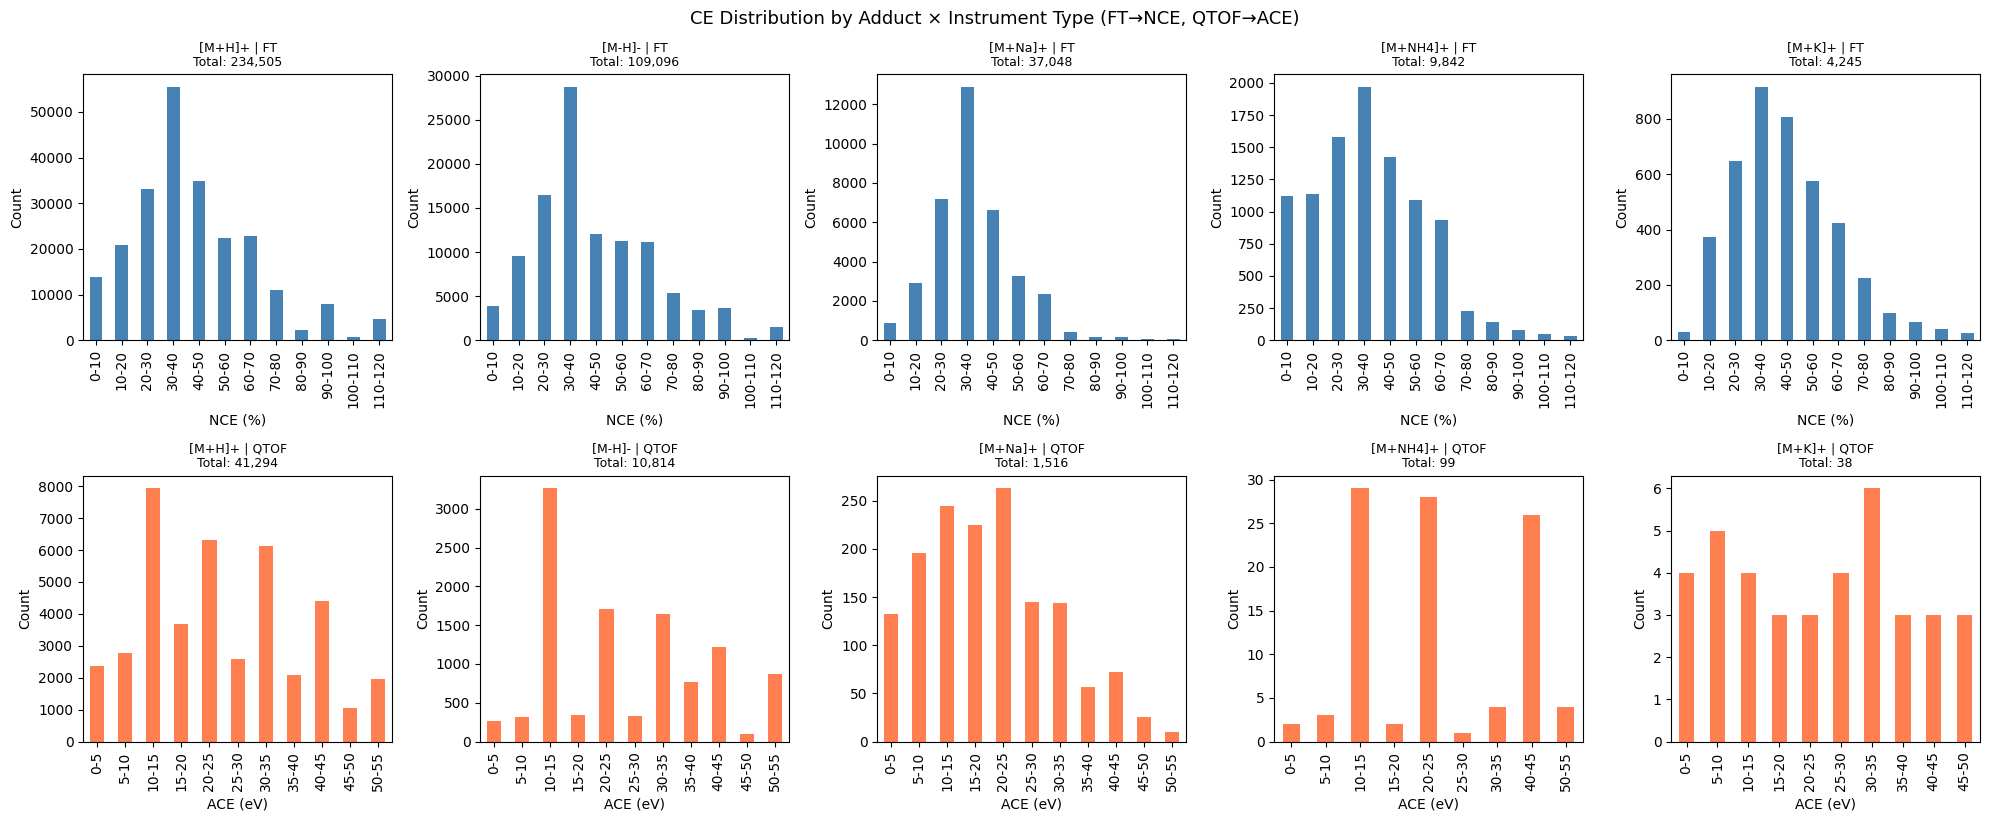

In [12]:
# CE distribution per adduct × instrument type: FT (row 1) → NCE, QTOF (row 2) → ACE
inst_ce_cfg = {
    'FT':   ('nce', 'NCE (%)', 10, range(0, 130, 10)),
    'QTOF': ('ace', 'ACE (eV)',  5, range(0, 60, 5)),
}
colors = {'FT': 'steelblue', 'QTOF': 'coral'}

combo_counts = (
    nist_spectra_df
    .groupby(['prec_type', 'inst_type'])
    .size()
    .sort_values(ascending=False)
)

ft_combos   = [(pt, it) for pt, it in combo_counts.index if it == 'FT']
qtof_combos = [(pt, it) for pt, it in combo_counts.index if it == 'QTOF']
ncols = max(len(ft_combos), len(qtof_combos), 1)

fig, axes = plt.subplots(2, ncols, figsize=(ncols * 4, 8), sharey=False)

for row, (inst_type, combos) in enumerate([('FT', ft_combos), ('QTOF', qtof_combos)]):
    ce_col, ce_label, bin_size, bin_starts = inst_ce_cfg[inst_type]
    bins = list(bin_starts)
    bin_labels = [f"{b}-{b + bin_size}" for b in bins[:-1]]

    for col, (prec_type, _) in enumerate(combos):
        ce_vals = nist_spectra_df.loc[
            (nist_spectra_df['prec_type'] == prec_type) &
            (nist_spectra_df['inst_type'] == inst_type),
            ce_col,
        ].dropna()

        binned_data = {lbl: 0 for lbl in bin_labels}
        for val in ce_vals:
            idx = int((val - bins[0]) // bin_size)
            if 0 <= idx < len(bin_labels):
                binned_data[bin_labels[idx]] += 1

        binned_series = pd.Series(binned_data)
        binned_series = binned_series[binned_series > 0]

        ax = axes[row, col]
        if len(binned_series) > 0:
            binned_series.plot(kind='bar', ax=ax, color=colors[inst_type])
        ax.set_title(f"{prec_type} | {inst_type}\nTotal: {len(ce_vals):,}", fontsize=9)
        ax.set_xlabel(ce_label)
        ax.set_ylabel('Count')
        ax.tick_params(axis='x', rotation=90)

    for col in range(len(combos), ncols):
        axes[row, col].set_visible(False)

plt.tight_layout()
plt.suptitle('CE Distribution by Adduct × Instrument Type (FT→NCE, QTOF→ACE)', fontsize=13, y=1.02)
plt.show()
